# **Tutorial:** Custom YOLO Object Detection with RoboFlow

In this tutorial, you'll learn how to create a custom YOLO object detection model using your own classes and annotations with RoboFlow.

Elaborado por: Alexander Fernández Pérez

### **Step 1: Install Required Dependencies**

In [1]:
%pip install --upgrade ultralytics
%pip install opencv-python
%pip install roboflow
%pip install matplotlib
# %pip install numpy==1.26.4 --force-reinstall   # Solo descomentar si aparece un error de numpy (no funciona en Python 3.13+)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached opencv_python_headless-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python_headless-5.0.0.93-cp37-abi3-win_amd64.whl (43.8 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### **Step 2: Import Required Libraries**

In [1]:
import cv2
from roboflow import Roboflow
from ultralytics import YOLO
import matplotlib.pyplot as plt
import numpy as np
import os
from IPython.display import Image, display

In [2]:
#luego de Restart
OUTPUT_DIR = 'runs/detect/custom_yolo_model'

### **Step 3: Set Up RoboFlow Account**

1. Go to RoboFlow and create a free account
2. Create a new project and select "Object Detection" as project type
3. Choose "YOLOv26" as the model format

> **📝 Qué hacer (Paso 3):**
> 1. Entra a https://roboflow.com → *Sign up* (puedes usar Google).
> 2. Crea tu *workspace* (gratis, "Public plan").
> 3. **New Project** → tipo **Object Detection** → ponle un nombre (ej. `mis_objetos`) y en *What are you detecting?* escribe algo general (ej. `objetos`).
> 4. El formato "YOLO26" se elige recién al **exportar** (Paso 5), no ahora.

### **Step 4: Upload and Annotate Your Images**

#### Using RoboFlow Web Interface:

1. Click "Upload" to add your images
2. Use the annotation tool to draw bounding boxes around objects
3. Assign the correct class labels to each bounding box
4. Apply preprocessing and augmentation as needed

> **📝 Qué hacer (Paso 4):**
> - **Fotos:** al menos **25 por objeto** (mejor 30–40), tomadas con tu **webcam o celular**: distintos ángulos, distancias, fondos y luz. Incluye algunas con **los 2 objetos juntos**.
> - **Upload:** arrastra las fotos → *Save and Continue*.
> - **Annotate:** abre cada imagen → dibuja una caja (herramienta *Bounding Box*, tecla `B`) **ajustada** al objeto → escribe la clase (ej. `taza`, `control`). Usa siempre el **mismo nombre** de clase.
> - Cuando termines: **Add images to Dataset** → split **70% train / 20% valid / 10% test**.

### **Step 5. Download your Custom your Dataset**

1. In RoboFlow, go to your project dashboard
2. Click "Generate" to create a dataset version
3. Apply any desired augmentations
4. Click "Export" and select "YOLOv**x**" format (**x** the version you are using)
5. Copy the download code

> **📝 Qué hacer (Paso 5):**
> 1. Menú izquierdo **Versions** → *Create New Version*.
> 2. **Preprocessing:** Auto-Orient + Resize 640×640 (vienen por defecto).
> 3. **Augmentation:** por ejemplo *Flip horizontal*, *Rotation ±15°*, *Brightness ±25%* → output **x3** (así tus ~50 fotos se vuelven ~150 de entrenamiento).
> 4. **Create** → **Download Dataset** → formato **YOLO26** (si no aparece, usa **YOLOv11**, es el mismo formato) → *Show download code* → pestaña **Jupyter** → copia el código.
> 5. Pega ese código en la celda de abajo **reemplazando** lo que está (ahí va tu `api_key`, tu workspace y tu proyecto).

In [3]:
# 👇 PEGA AQUÍ el código que te da Roboflow (Download Dataset → Jupyter). Debe verse así:
from roboflow import Roboflow
rf = Roboflow(api_key="RNavx6MnblnGA861HBqC")
project = rf.workspace("alexanderytvideo").project("dos_objetos")
version = project.version(1)
dataset = version.download("yolo26")

print("Dataset descargado en:", dataset.location)


                

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to dos_objetos-1 in yolo26:: 100%|██████████| 170/170 [00:00<00:00, 713.01it/s]

Dataset descargado en: c:\Users\pauls\Desktop\Yachay\3_Fundamentos_ia\15clase\dos_objetos-1


### **Step 6: Train Your Custom YOLO Model**

In [4]:
OUTPUT_DIR = 'runs/detect/custom_yolo_model'

# Load the YOLO model with custom configuration
model = YOLO('yolo26n.pt')  # Using nano version as base

# Train the model on your custom dataset
results = model.train(
    data=f'{dataset.location}/data.yaml',  # Path to dataset config
    epochs=50,  # Number of training epochs (50 porque el dataset es pequeño; en CPU toma unos minutos)
    imgsz=640,  # Image size
    batch=8,   # Batch size
    name='custom_yolo_model',  # Name for the training run
    exist_ok=True  # Sobrescribe la carpeta si vuelves a entrenar (evita custom_yolo_model2, 3...)
)

Ultralytics 8.4.210  Python-3.13.7 torch-2.13.0+cpu CPU (AMD Ryzen 5 3450U with Radeon Vega Mobile Gfx)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\pauls\Desktop\Yachay\3_Fundamentos_ia\15clase\dos_objetos-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.

### **Step 7: Evaluate Your Model**

Ultralytics 8.4.210  Python-3.13.7 torch-2.13.0+cpu CPU (AMD Ryzen 5 3450U with Radeon Vega Mobile Gfx)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.2±0.0 ms, read: 44.4±7.9 MB/s, size: 38.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\pauls\Desktop\Yachay\3_Fundamentos_ia\15clase\dos_objetos-1\valid\labels.cache... 17 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 3.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.4s/it 2.8s7.8s
                   all         17         18      0.921      0.967      0.972      0.822
               botella          8          8          1      0.934      0.995      0.898
                 plato         10         10      0.842          1       0.95      0.745
Speed

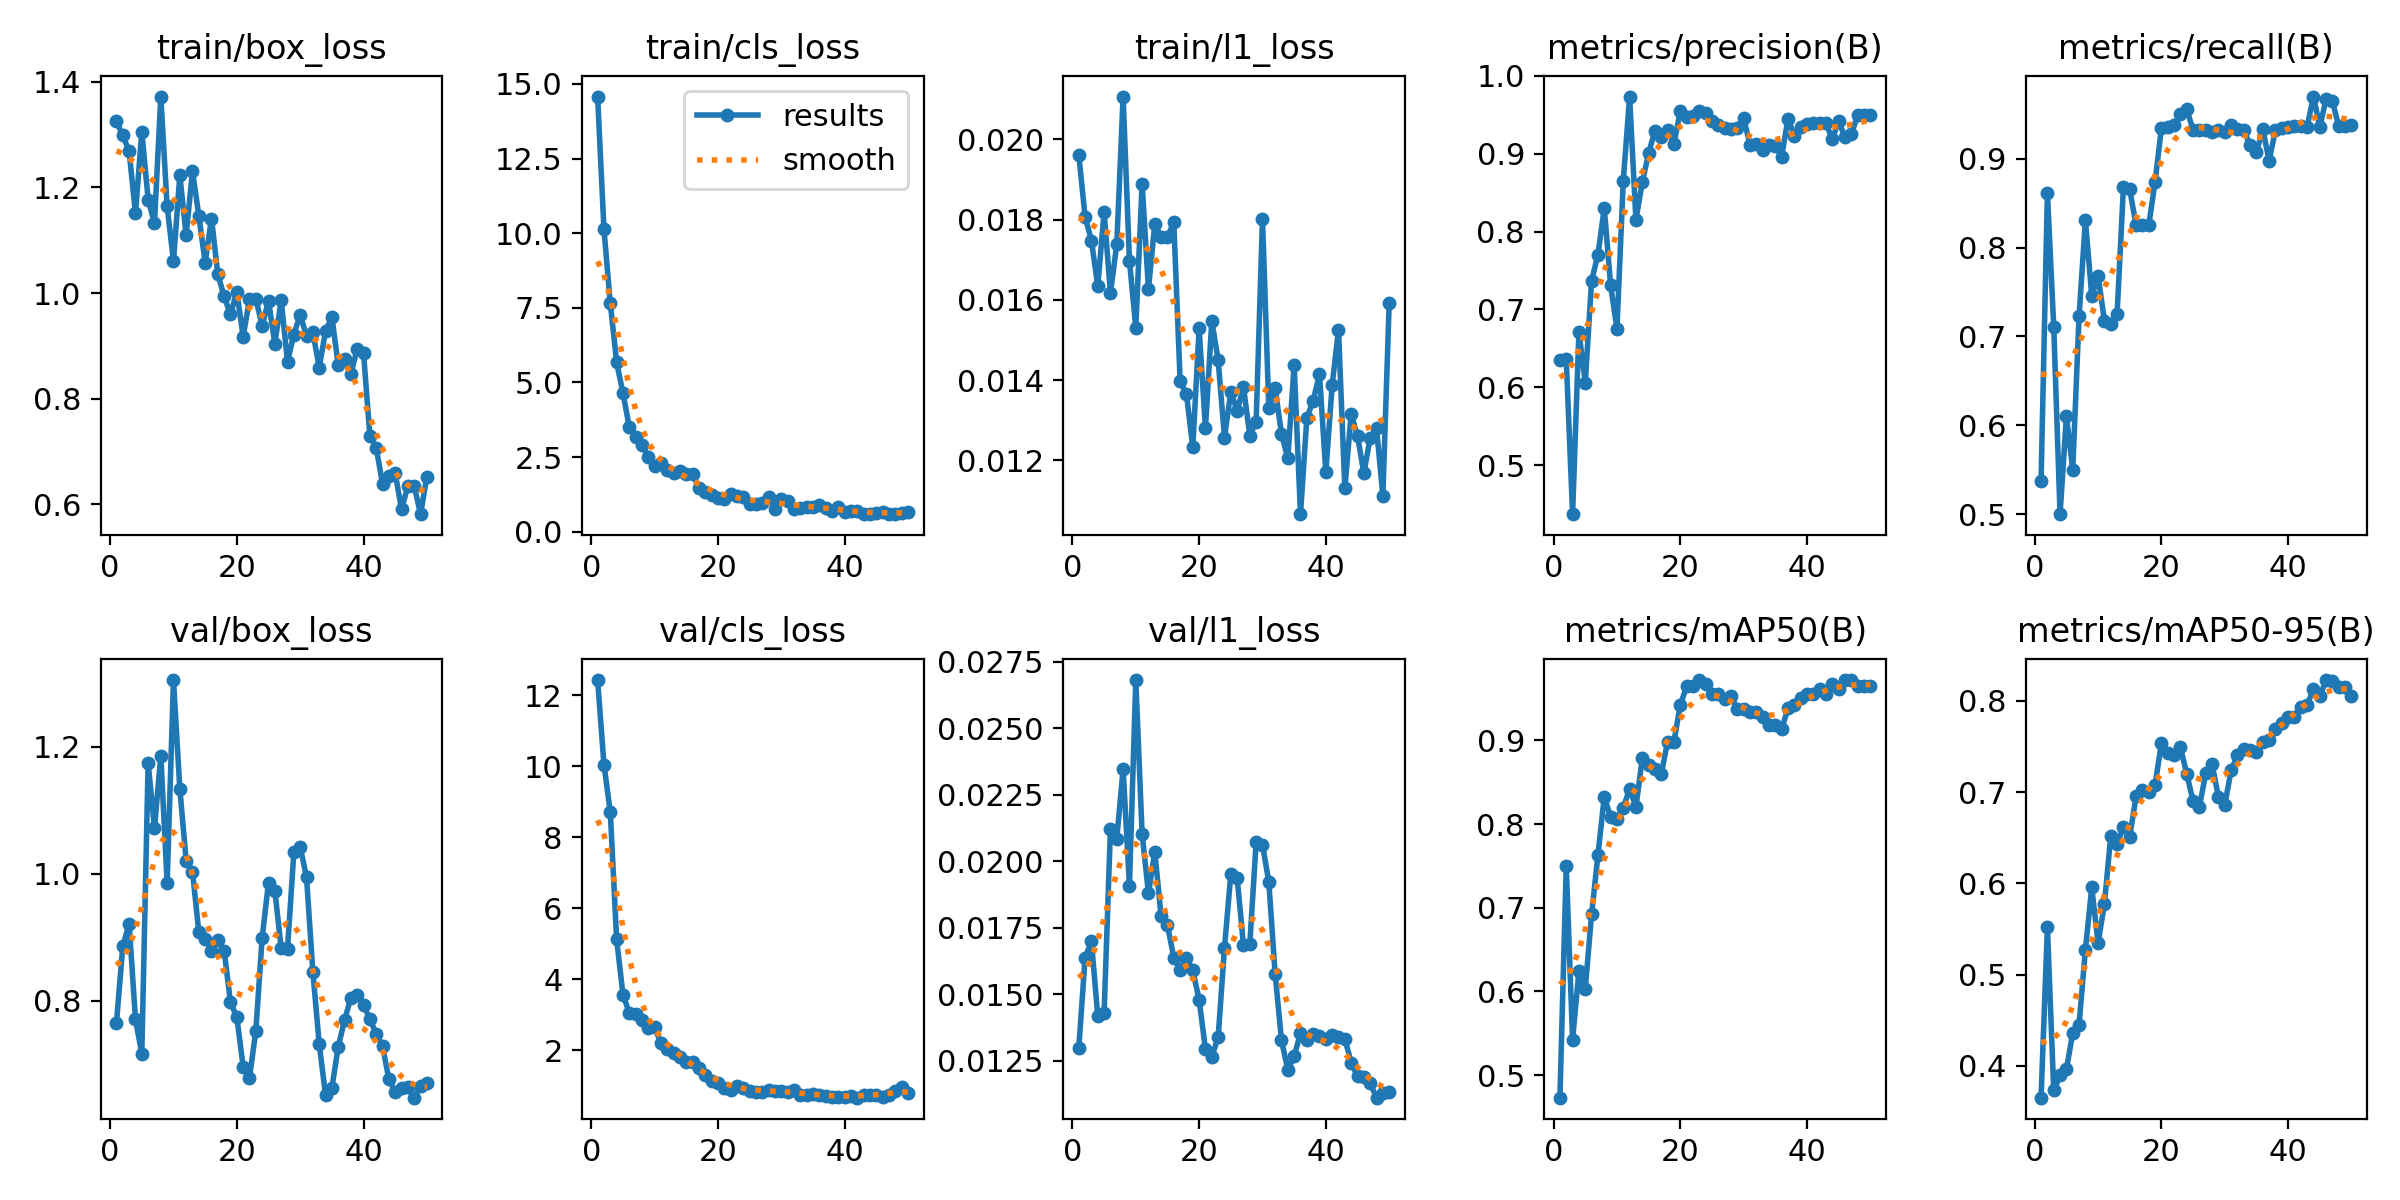

confusion_matrix.png


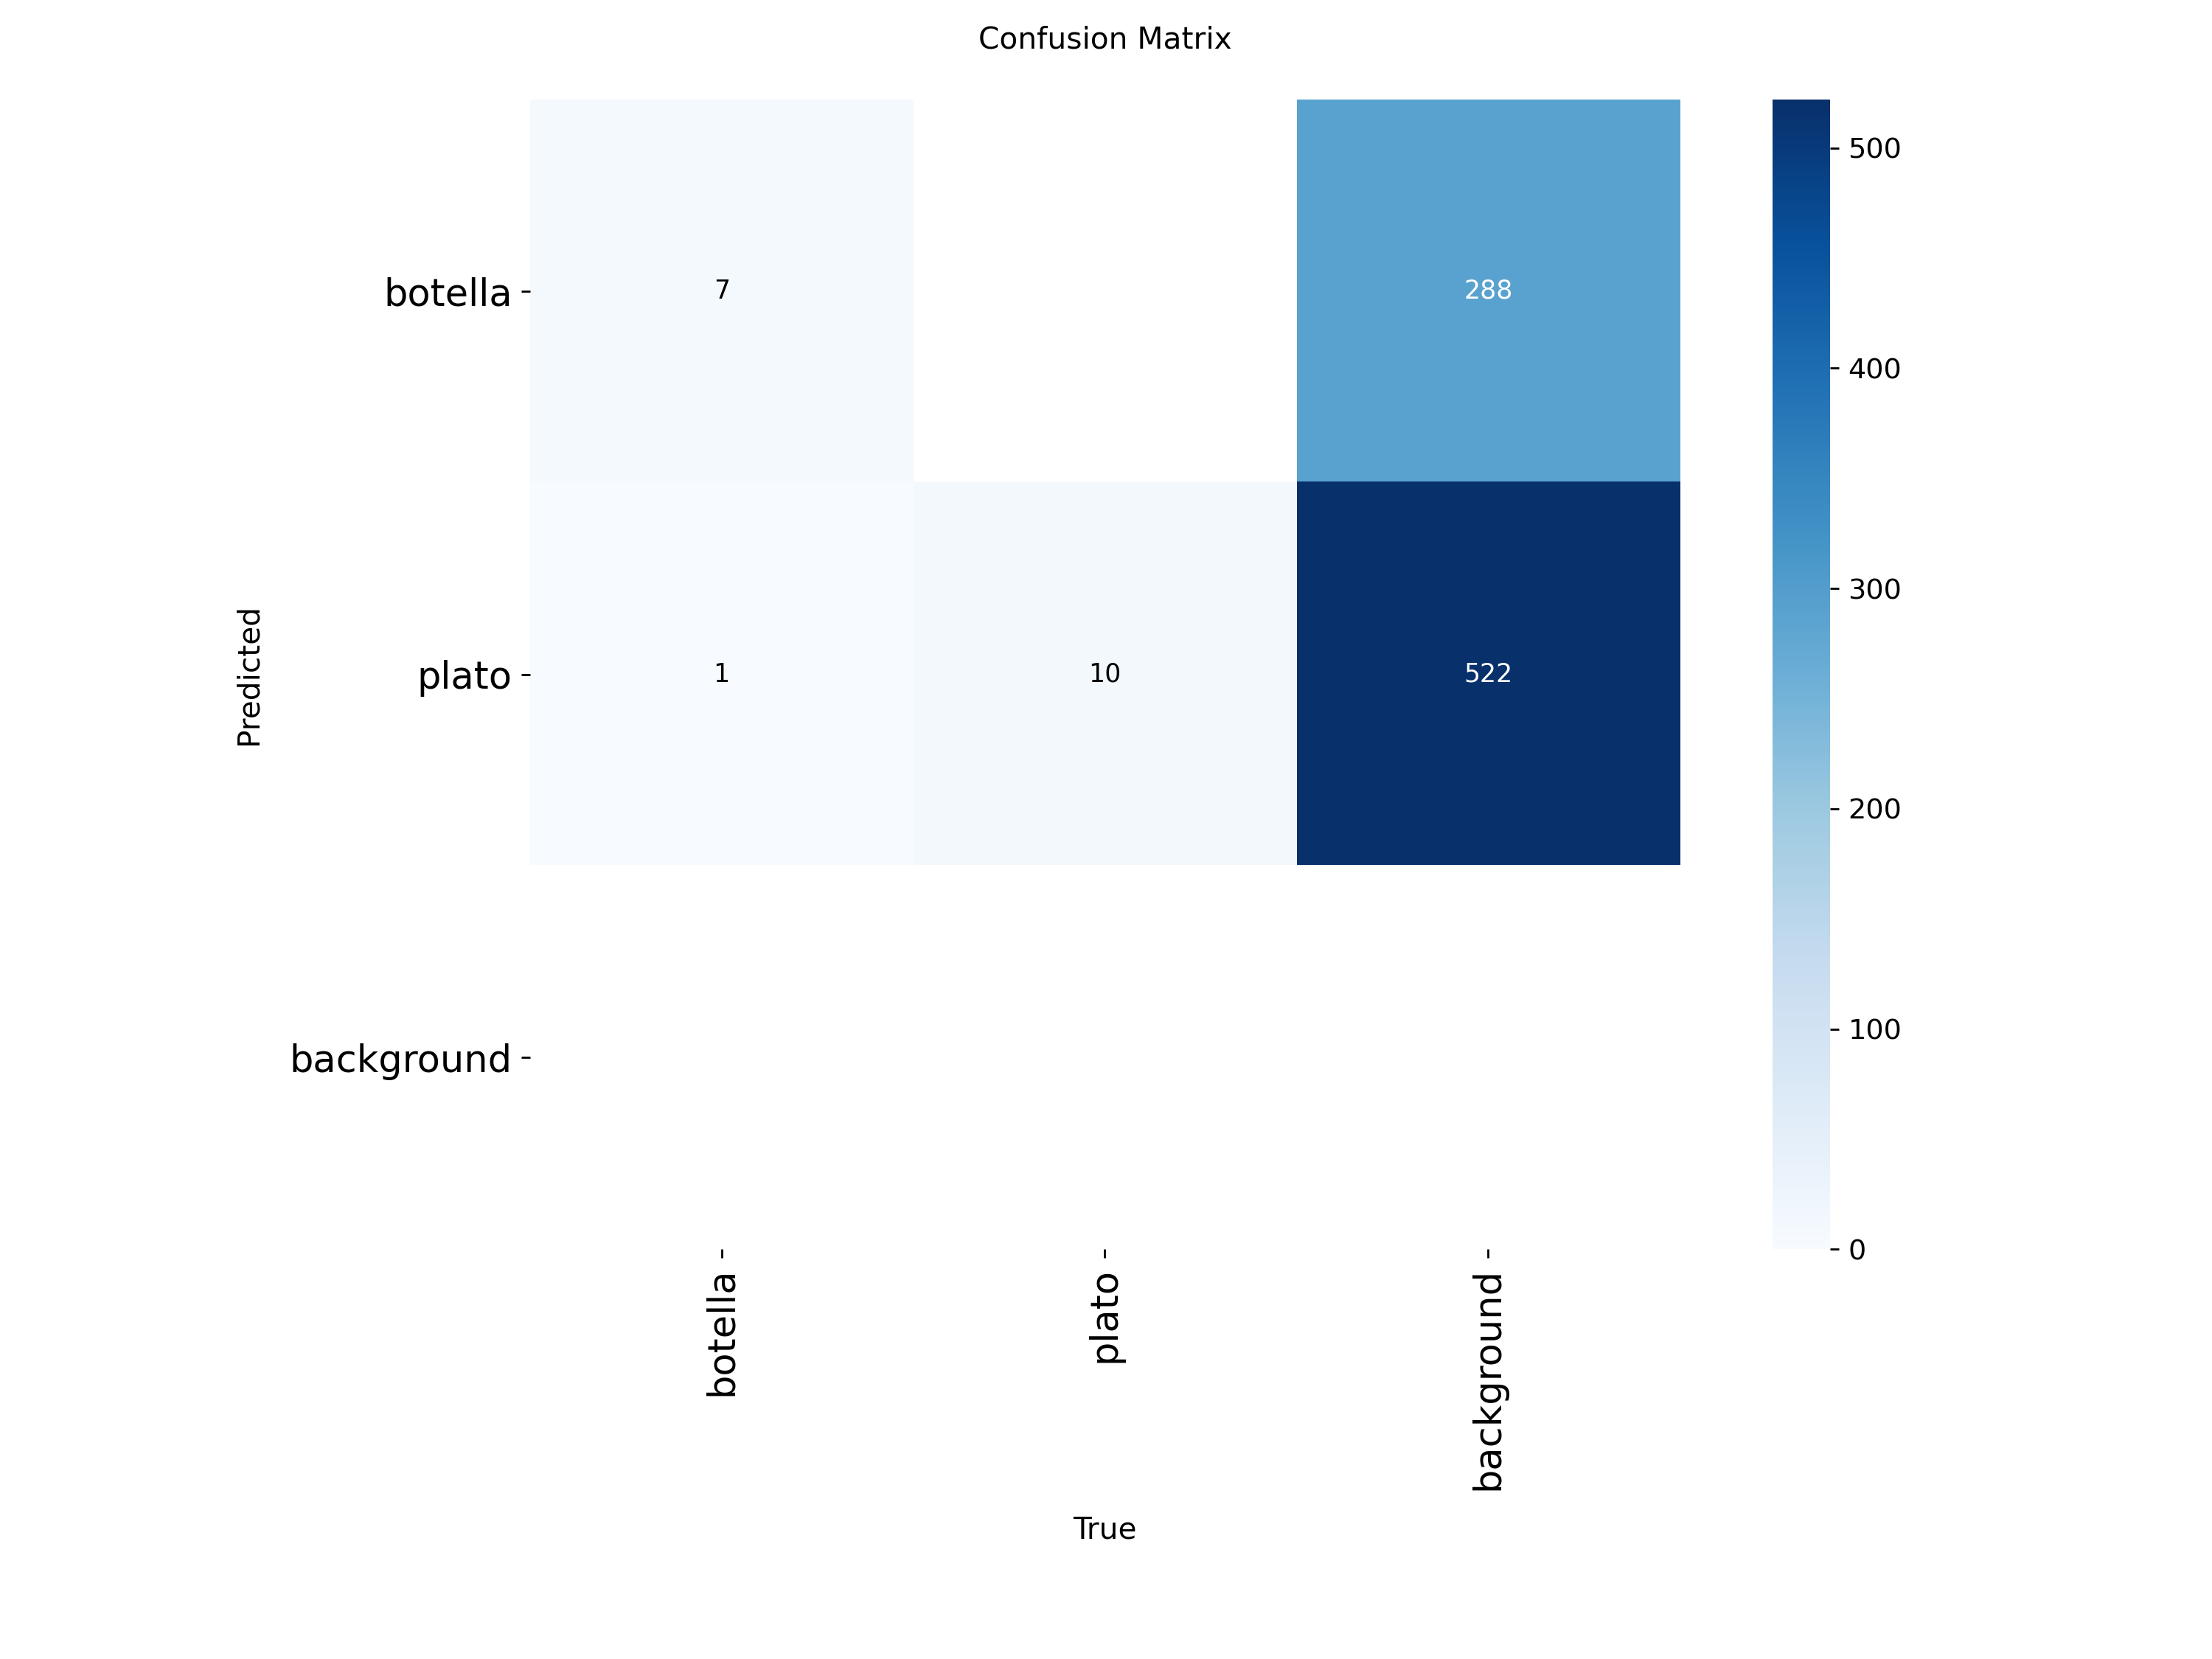

val_batch0_pred.jpg


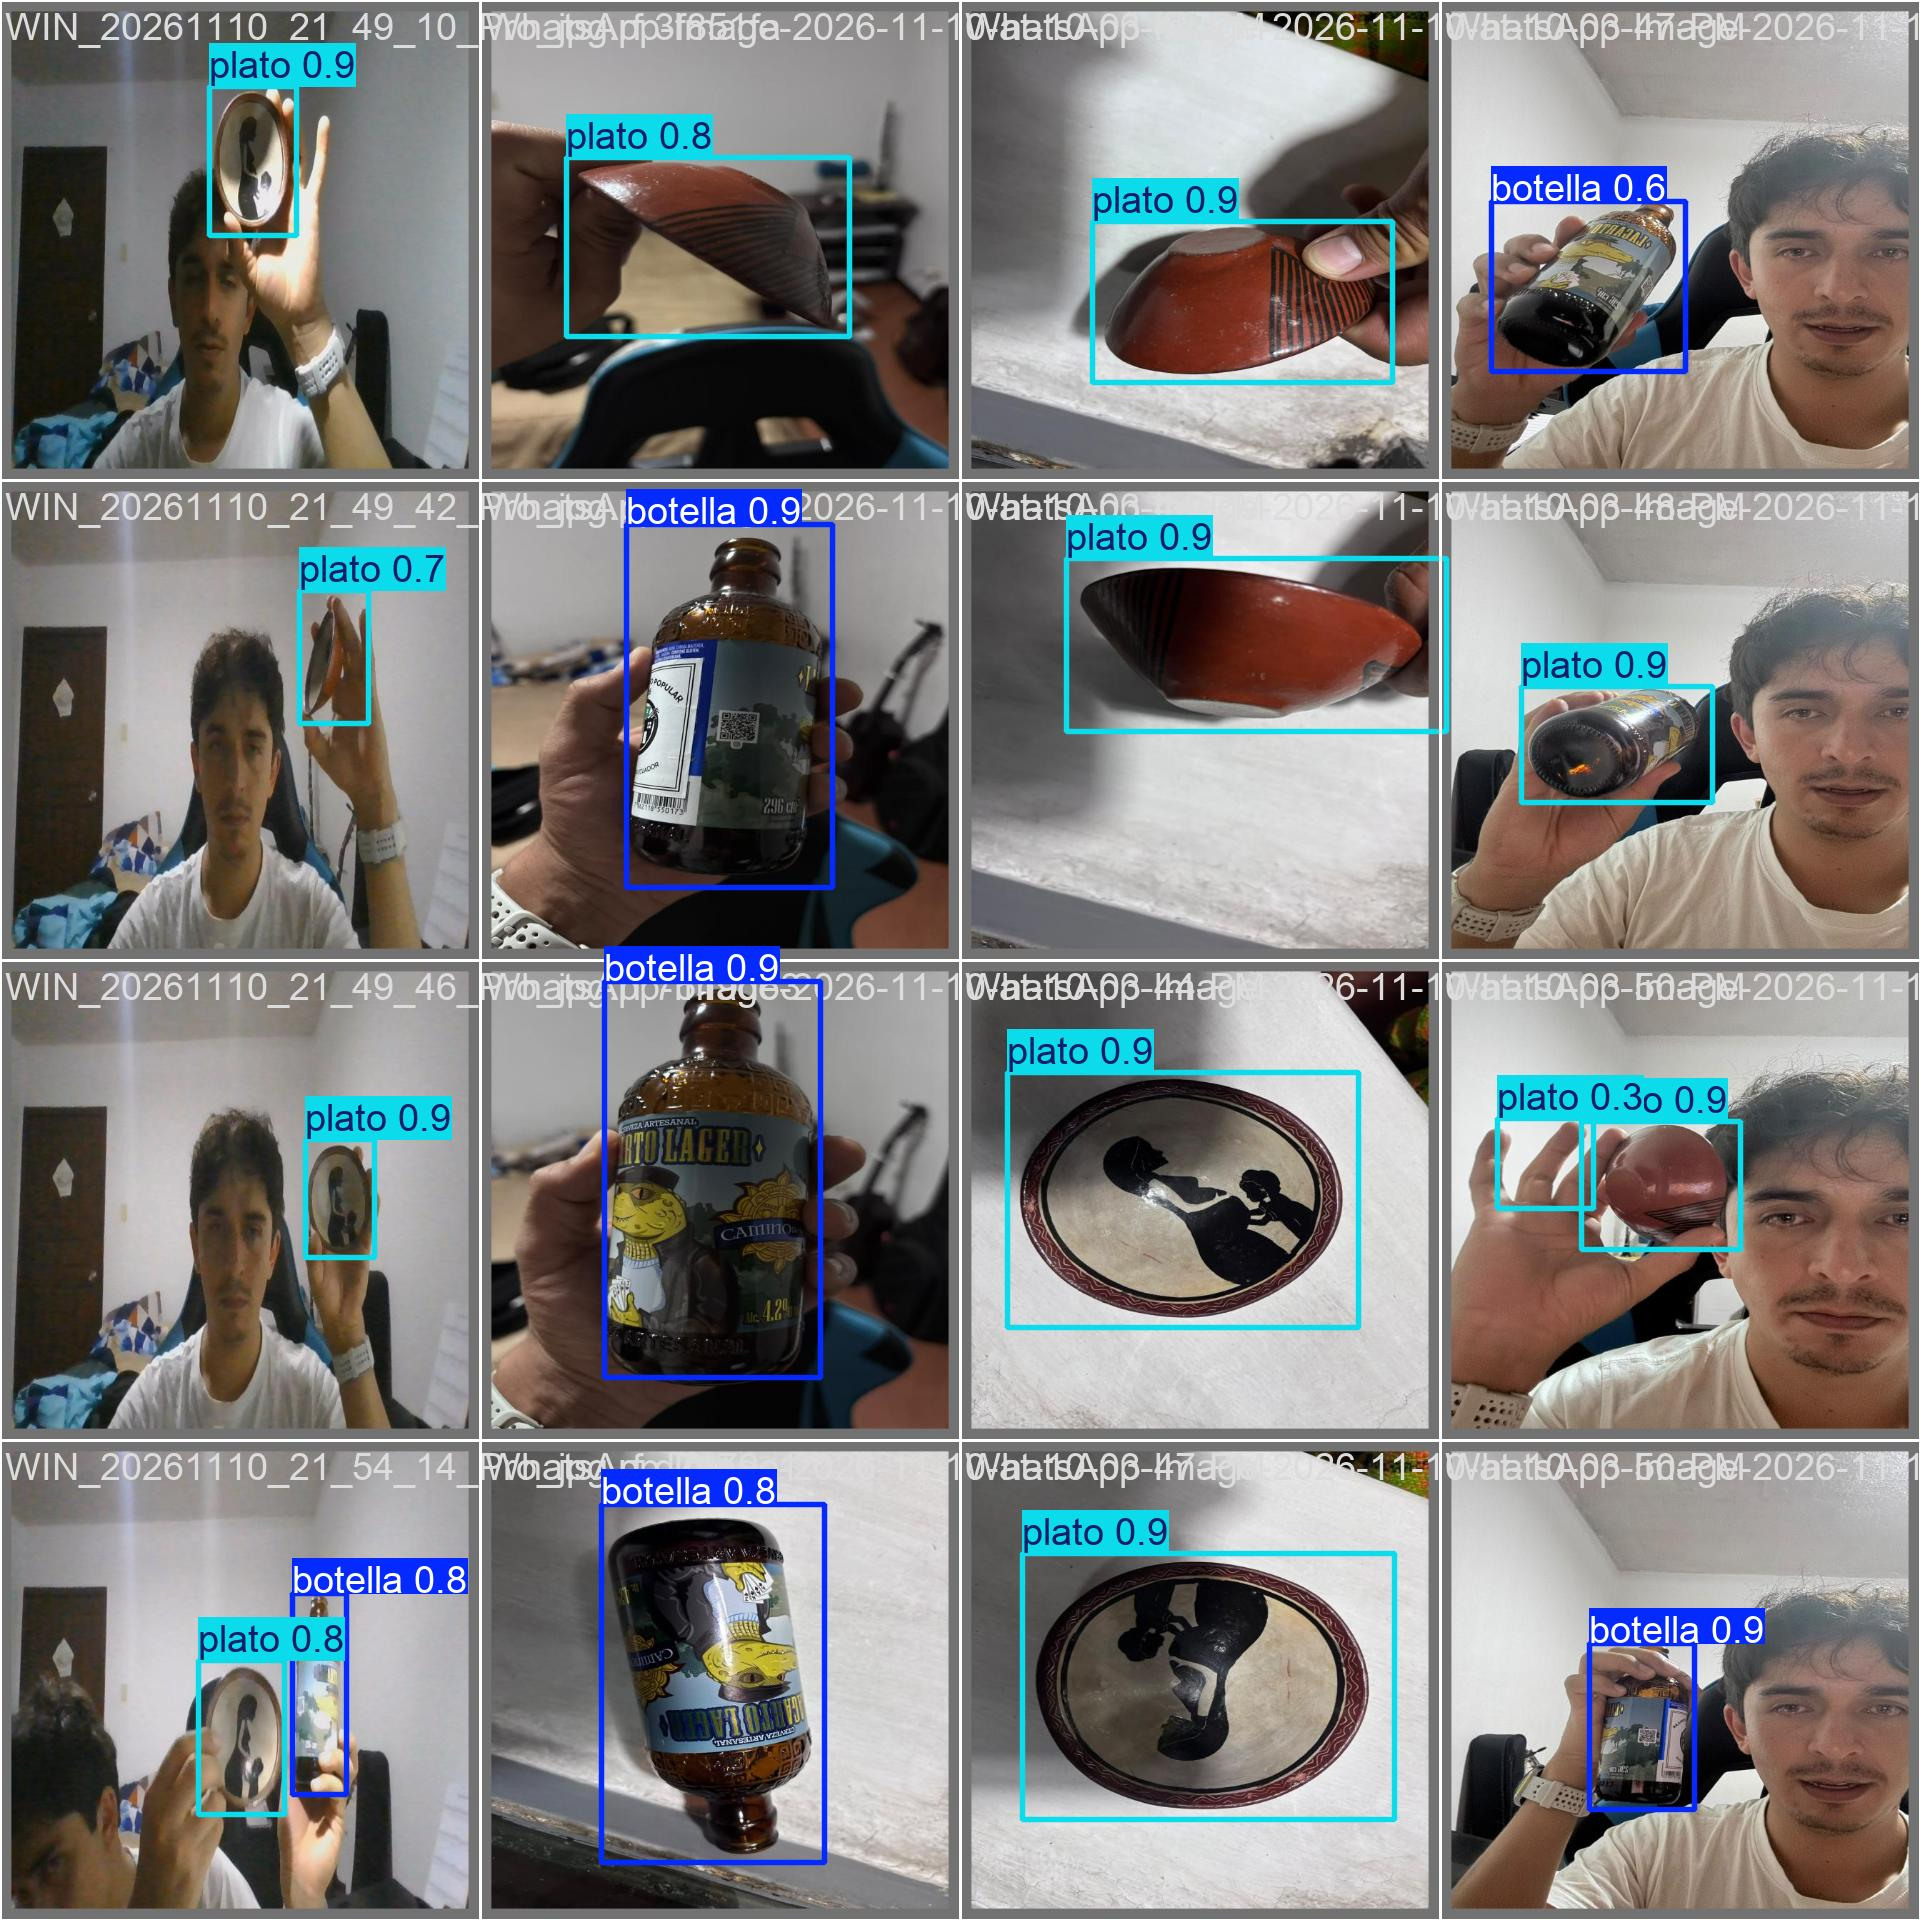

In [5]:
# Evaluate model performance
best = YOLO(f'{OUTPUT_DIR}/weights/best.pt')
metrics = best.val(data=f'{dataset.location}/data.yaml')  # Validate the model
print(f"mAP50-95: {metrics.box.map:.3f}")
print(f"mAP50:    {metrics.box.map50:.3f}")
print(f"Precision: {metrics.box.mp:.3f}")
print(f"Recall:    {metrics.box.mr:.3f}")

# Métricas por clase
for i, name in best.names.items():
    p, r, ap50, ap = metrics.box.class_result(i)
    print(f"{name:>12} | P={p:.2f}  R={r:.2f}  mAP50={ap50:.2f}  mAP50-95={ap:.2f}")

# Show some validation results (gráficos que genera YOLO)
for f in ['results.png', 'confusion_matrix.png', 'val_batch0_pred.jpg']:
    path = os.path.join(OUTPUT_DIR, f)
    if os.path.exists(path):
        print(f); display(Image(filename=path, width=800))

Análisis de resultados: 
- mAP50 = 0.97: el modelo encuentra y ubica muy bien los dos objetos.
- Botella: todo lo que detecta como botella es correcto (Precision = 1), pero se le escapó 1 botella (Recall = 0.93).
- Plato: encuentra todos los platos (Recall = 1), pero a veces marca como plato algo que no lo es (Precision = 0.84).
- Matriz de confusión: 17 de 18 objetos bien clasificados; solo 1 botella fue confundida con plato.

### **Step 8: Test Your Custom Model on an Image**


image 1/1 c:\Users\pauls\Desktop\Yachay\3_Fundamentos_ia\15clase\test.jpeg: 640x480 2 botellas, 281.7ms
Speed: 11.7ms preprocess, 281.7ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 480)


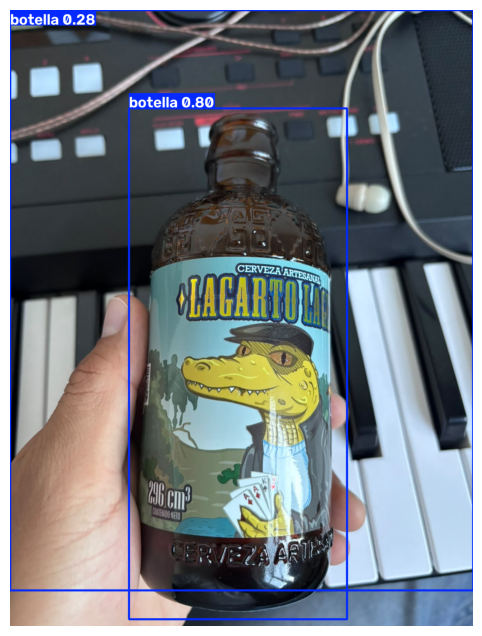

In [8]:
# Load your custom trained model
custom_model = YOLO(f'{OUTPUT_DIR}/weights/best.pt')

# Test on a sample image (toma una foto NUEVA que no subiste a Roboflow y guárdala junto al notebook)
results = custom_model('test.jpeg', conf=0.25)

# Display results
%matplotlib inline
for result in results:
    img = result.plot()  # Plot detections
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 8))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.show()

### **Step 9: Test Your Custom Model on Video**

In [4]:
# Detección en tiempo real con la WEBCAM (se abre una ventana aparte; presiona "q" para salir)
import time

custom_model = YOLO(f'{OUTPUT_DIR}/weights/best.pt')
cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)  # 0 = webcam principal (prueba 1 si no abre)

if not cap.isOpened():
    raise RuntimeError("No se pudo abrir la webcam")

prev = time.time()
while True:
    ok, frame = cap.read()
    if not ok:
        break

    results = custom_model(frame, conf=0.5, verbose=False)  # detectar en el frame
    annotated = results[0].plot()                           # dibujar cajas y clases

    # FPS y número de objetos detectados
    now = time.time(); fps = 1 / (now - prev); prev = now
    cv2.putText(annotated, f"FPS: {fps:.1f} | Objetos: {len(results[0].boxes)}",
                (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

    cv2.imshow("Custom YOLO - Webcam (q para salir)", annotated)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

In [5]:
%pip uninstall -y opencv-python-headless opencv-python
%pip install opencv-python

Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 📄 Documentación

**Objetivo:** entrenar un detector YOLO para reconocer 2 objetos propios en tiempo real con la webcam.

**Clases:** `plato` y `botella`

**Dataset (Roboflow):**
- 83 fotos propias tomadas con webcam y celular (objetos solos y juntos, en la mano y sobre superficies, distintos fondos).
- Anotación manual con cajas (bounding boxes).
- División: 58 train / 17 valid / 8 test (70/20/10).
- Preprocesamiento: Auto-Orient y Resize 640×640.
- Exportado en formato YOLO26.

**Entrenamiento:**
- Modelo base: YOLO26n (preentrenado).
- 50 épocas, imgsz 640, batch 8.
- En CPU (AMD Ryzen 5), duración aprox. 44 minutos.

**Resultados:** mAP50 = 0.97, mAP50-95 = 0.82, Precision = 0.92, Recall = 0.97.

**Prueba en tiempo real (webcam):**
- FPS aprox.: ___
- Funciona bien cuando: ___
- Falla cuando: ___

## **Activity: Create Your Custom Detector**

1. **Create a RoboFlow account** and set up a new project
2. **Upload at least 25 images** of your custom objects (at least 2)
3. **Annotate all images** with bounding boxes and class labels
4. **Train a YOLO model** on your custom dataset
5. **Test your model** on new images and evaluate its performance
6. **Implement real-time detection** with your custom classes

## **Grading Rubric:**

| **Criteria** | **Points** | **Description** |
|-------------|-----------|----------------|
| **1. Dataset Creation** | 4 | Successfully creates and annotates a custom dataset with at least 25 images and multiple classes in RoboFlow. |
| **2. Model Training** | 1 | Properly trains a YOLOv26 model on the custom dataset with appropriate hyperparameters. |
| **3. Model Evaluation** | 1 | Evaluates model performance with appropriate metrics and provides analysis of results. |
| **4. Custom Detection** | 3 | Implements real-time detection with custom classes and displays results correctly. You have to use video from your webcam, no images or saved videos allowed. |
| **5. Documentation** | 1 | Provides clear documentation of the process, including dataset details and model performance. |

**Total: 10 points**

## **Tips for Success:**

- **Quality over quantity**: Well-annotated images are more important than many poorly annotated ones
- **Class balance**: Try to have a similar number of examples for each class
- **Variety**: Include different angles, lighting conditions, and backgrounds
- **Augmentation**: Use RoboFlow's augmentation features to expand your dataset

<p style="text-align: right; font-size:14px; color:gray;">
<b>Prepared by:</b><br>
Manuel Eugenio Morocho-Cayamcela
</p>